<a href="https://colab.research.google.com/github/ruchisharmaku-debug/AI-crop-disease-detection/blob/main/Copy_of_Crop_disease_detection_model_pred.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import urllib.request
import matplotlib.pyplot as plt
import kagglehub
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Download latest version of the dataset
dataset_path = kagglehub.dataset_download("nirmalsankalana/potato-viral-disease-dataset")
print("Path to dataset files:", dataset_path)
print("Classes available:", os.listdir(dataset_path))

100%|██████████| 799M/799M [00:42<00:00, 19.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/nirmalsankalana/potato-viral-disease-dataset/versions/1
Classes available: ['Potato___leafroll_virus', 'Potato___mosaic_virus', 'Potato___healthy', 'Potato___spindle_tuber_viroid']


In [5]:
# Set parameters
BATCH_SIZE = 32
IMAGE_SIZE = (256, 256)
EPOCHS = 10

# Load Data via image_dataset_from_directory (with validation split)
train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_dataset.class_names
print("Class Names:", class_names)

Found 1413 files belonging to 4 classes.
Using 1131 files for training.
Found 1413 files belonging to 4 classes.
Using 282 files for validation.
Class Names: ['Potato___healthy', 'Potato___leafroll_virus', 'Potato___mosaic_virus', 'Potato___spindle_tuber_viroid']


In [6]:
# Performance optimization using AUTOTUNE
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)

In [7]:
# Model Architecture
data_augmentation = tf.keras.Sequential([
  layers.RandomFlip("horizontal_and_vertical"),
  layers.RandomRotation(0.2),
  layers.RandomZoom(0.2),
])

model = models.Sequential([
    layers.InputLayer(input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)),
    layers.Rescaling(1./255),
    data_augmentation,
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,839,492 (56.61 MB)

 Trainable params: 14,839,492 (56.61 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Compile the model
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 51s 355ms/step - accuracy: 0.6012 - loss: 1.0303 - val_accuracy: 0.6986 - val_loss: 0.6815
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step - accuracy: 0.7303 - loss: 0.6255 - val_accuracy: 0.7518 - val_loss: 0.5057
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - accuracy: 0.7825 - loss: 0.4907 - val_accuracy: 0.8227 - val_loss: 0.4146
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.8037 - loss: 0.4187 - val_accuracy: 0.8546 - val_loss: 0.3271
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8329 - loss: 0.3754 - val_accuracy: 0.8369 - val_loss: 0.3919
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step - accuracy: 0.8506 - loss: 0.3643 - val_accuracy: 0.8440 - val_loss: 0.3659
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - accuracy: 0.8506 - loss: 0.3396 - val_accuracy: 0.8617 - val_loss: 0.2908
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - accuracy: 0.8523 - loss: 0.3417 - val_accuracy: 0.8688 -

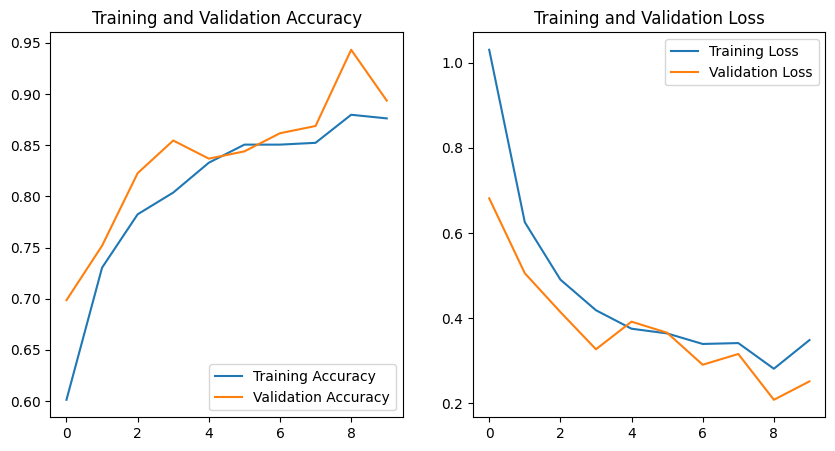

In [9]:
# Plotting the training results
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(EPOCHS)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [10]:
# Save the model
model.save("crop_disease_model.keras")
print("Model saved successfully as crop_disease_model.keras")

Model saved successfully as crop_disease_model.keras


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step
This image most likely belongs to Potato___mosaic_virus with a 85.23 percent confidence.


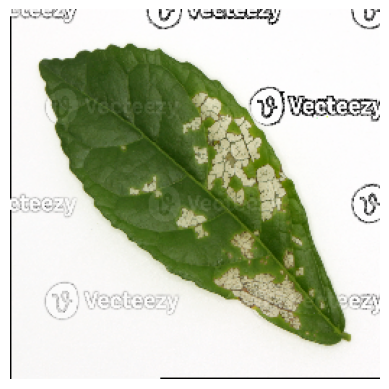

In [ ]:
def predict_image(img_path):
    img = tf.keras.utils.load_img(
        img_path, target_size=IMAGE_SIZE
    )
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0) # Create a batch

    predictions = model.predict(img_array)
    score = (predictions[0])

    print("This image most likely belongs to {} with a {:.2f} percent confidence."
        .format(class_names[np.argmax(score)], 100 * np.max(score)))

    plt.imshow(img)
    plt.axis('off')
    plt.show()

# Uncomment and test with your image path:
predict_image("/content/leaf-disease.2.webp")


In [11]:
model.save("crop_disease_model.h5")

In [12]:
%%writefile app.py
import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

st.set_page_config(page_title="Potato Crop Disease Detection", page_icon="🥔")
st.title("🥔 AI Potato Crop Disease Detection")
st.write("Upload a potato leaf image to detect viral diseases.")

@st.cache_resource
def load_model():
    return tf.keras.models.load_model("crop_disease_model.h5")

model = load_model()
input_shape = model.input_shape[1:3]

class_names = [
    'Potato___spindle_tuber_viroid',
    'Potato___mosaic_virus',
    'Potato___leafroll_virus',
    'Potato___healthy'
]

uploaded_file = st.file_uploader("Choose a leaf image...", type=["jpg", "jpeg", "png"])

if uploaded_file is not None:
    image = Image.open(uploaded_file).convert("RGB")
    st.image(image, caption="Uploaded Leaf Image", use_container_width=True)

    img = image.resize(input_shape)
    img_array = np.array(img, dtype=np.float32) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    predictions = model.predict(img_array)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = np.max(predictions[0]) * 100

    st.success(f"**Prediction:** {predicted_class}")
    st.info(f"**Confidence:** {confidence:.2f}%")

Writing app.py


In [15]:
!pkill -f streamlit
!pkill -f cloudflared
!nohup streamlit run app.py --server.port 8501 > streamlit.log 2>&1 &
!nohup cloudflared tunnel --url http://localhost:8501 > cloudflared.log 2>&1 &
!sleep 5 && grep -o 'https://[-0-9a-z]*\.trycloudflare\.com' cloudflared.log | head -n 1

In [16]:
!grep -o 'https://[-0-9a-z]*\.trycloudflare\.com' cloudflared.log | head -n 1

https://george-riding-angeles-corporations.trycloudflare.com
